# Search: Solving a Maze Using a Goal-based Agent

Student Name: [Add your name]

I have used the following AI tools: Claude (Anthropic), used to help write and test the code and the discussion text

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement the search algorithm BFS for planning paths through mazes.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [1]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "large_maze.txt", "open_maze.txt", "empty_maze.txt"]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [2]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [3]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

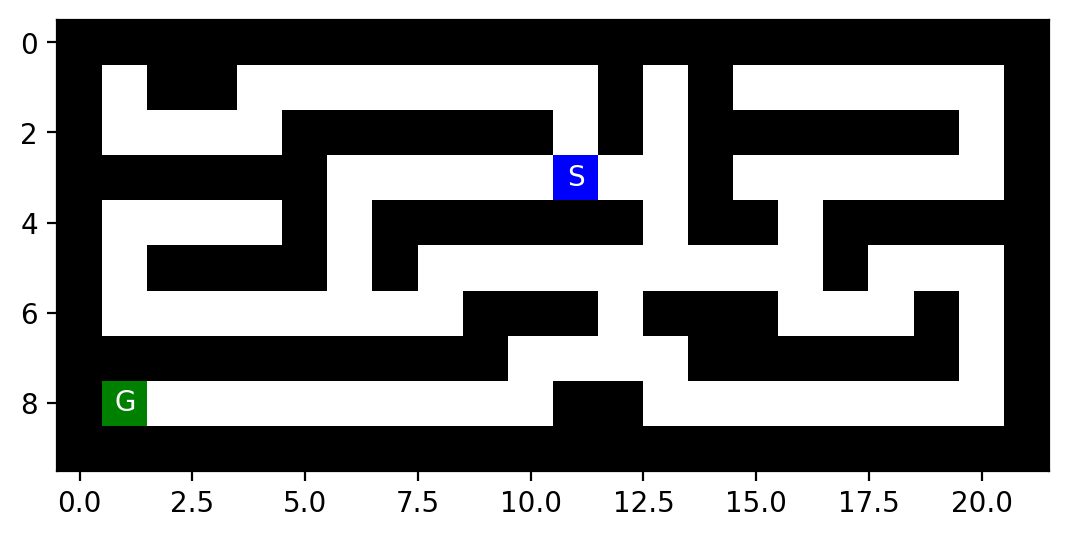

In [4]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [5]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [6]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment by Michael Hahsler
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [7]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [8]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['N', 'E', 'W', 'W', 'W', 'W', 'W', 'N', 'S', 'W']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [9]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: E
Following plan... step 1: E
Following plan... step 2: S
Following plan... step 3: E
Following plan... step 4: W
Following plan... step 5: S
Following plan... step 6: N
Following plan... step 7: N
Following plan... step 8: E
Following plan... step 9: N
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [10]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"
    
    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]
    
        while not node.parent is None:
            node = node.parent
            path.append(node)
        
        path.reverse()
        
        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithm for solving different mazes:
    - Breadth-first search (BFS)

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt), and
    - [empty maze](empty_maze.txt).

3. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [2 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

A **state** is the position `(row, col)` of the agent on a square that is not a wall.

* **Initial state:** the square marked `S` (`find_pos(maze, "S")`).
* **Actions:** $\text{ACTIONS}(s) \subseteq \{N, E, S, W\}$: move one square up, right, down or left. An action is applicable if the target square is inside the maze and not a wall `X`.
* **Transition model:** $\text{RESULT}((r, c), a) = (r + \Delta r, c + \Delta c)$ with $\Delta N = (-1, 0)$, $\Delta E = (0, +1)$, $\Delta S = (+1, 0)$, $\Delta W = (0, -1)$. It is deterministic.
* **Goal state:** $\text{IS-GOAL}(s)$ is true for the square marked `G`.
* **Path cost:** every action costs 1, so $g(n)$ is the number of steps = depth of the node = length of the plan.

Give some estimates for the problem size:

* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

* $d$: the number of steps of the shortest path from `S` to `G`. I measure it with BFS itself (it is the path length found in Task 2).
* $m$: with a `reached` set every state gets one node, so the tree can not be deeper than the largest distance from `S` to any free square. I get this value with a breadth-first flood fill from `S`. (Without any redundancy check the tree would be infinite because the agent can walk back and forth.)
* $b$: the largest number of applicable actions over all free squares. It is 4 in open areas; in corridors it is 2 or 3. Below the root, one action leads back to the parent, so a node has at most 3 useful children.

| maze | $n$ (free squares) | $d$ | $m$ | $b$ |
|---|---|---|---|---|
| small | 94 | 19 | 20 | 3 |
| large | 647 | 210 | 222 | 4 |
| open | 684 | 54 | 54 | 4 |
| empty | 100 | 14 | 16 | 4 |

## Task 2: Breadth-First Search [5 Points]

Implement this simple search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important note** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.


**Design.** Search information is stored only in the tree (`Node` with parent reference) and in the data structures `frontier` and `reached`; the map is only read, never modified (a marked *copy* is created only to draw the result). The code follows the textbook BFS (graph-search version): the `frontier` is a FIFO queue (`deque`), `reached` is a set of states that already have a node, and the goal test is done when a node is *generated*. The path is extracted from the goal node with `get_path_from_root()`. `plan_bfs()` returns the sequence of actions, so it can be used as the planning function of the `Planning_Agent` above. Children are generated in the order N, E, S, W.

*Nodes expanded* counts the nodes whose children were generated (the goal node is detected when it is generated and is not expanded).

In [11]:
import numpy as np
import maze_helper as mh
from collections import deque

# ---- Problem definition: actions and transition model (the maze is only READ, never modified) ----
ACTIONS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}   # (d_row, d_col)
ACTION_ORDER = ["N", "E", "S", "W"]                                  # order in which children are generated

def as_pos(p):
    """Convert a position to a tuple of plain Python ints (find_pos() returns numpy ints)."""
    return (int(p[0]), int(p[1]))

def as_goal_set(goal):
    """The goal can be one position (row, col) or a collection of positions (multiple goals)."""
    if len(goal) == 2 and np.isscalar(goal[0]):
        return {as_pos(goal)}
    return {as_pos(g) for g in goal}

def find_all(maze, what="G"):
    """All positions of a symbol in the maze (find_pos() only returns the first one)."""
    return [as_pos(p) for p in np.argwhere(maze == what)]

def applicable_actions(maze, pos):
    """Actions that do not lead into a wall (or out of the maze)."""
    acts = []
    for a in ACTION_ORDER:
        r, c = pos[0] + ACTIONS[a][0], pos[1] + ACTIONS[a][1]
        if 0 <= r < maze.shape[0] and 0 <= c < maze.shape[1] and mh.look(maze, (r, c)) != "X":
            acts.append(a)
    return acts

def transition(pos, action):
    """Transition model: the new state after doing `action` in state `pos`."""
    return (pos[0] + ACTIONS[action][0], pos[1] + ACTIONS[action][1])

def expand(maze, node):
    """EXPAND from the textbook: create the child nodes of `node` (every step costs 1)."""
    return [Node(transition(node.pos, a), node, a, node.cost + 1) for a in applicable_actions(maze, node.pos)]

def make_result(goal_node, status, expanded, max_depth, max_frontier, max_memory, visited, frontier_states):
    """Collect the solution and the performance measures in a dictionary."""
    path = goal_node.get_path_from_root() if goal_node is not None else None
    return {"status": status,                       # solution / failure / cutoff / aborted
            "path": path,                           # list of nodes from root to goal
            "positions": [n.pos for n in path] if path else None,
            "actions": [n.action for n in path[1:]] if path else None,   # the plan
            "cost": goal_node.cost if goal_node is not None else None,   # path cost
            "expanded": expanded,                   # number of nodes expanded
            "max_depth": max_depth,                 # maximum depth of the search tree
            "max_frontier": max_frontier,           # maximum size of the frontier
            "max_memory": max_memory,               # maximum number of nodes in memory
            "visited": visited,                     # states of expanded nodes (for the plot)
            "frontier": frontier_states}            # states still on the frontier at the end (for the plot)

In [12]:
def bfs(maze, start, goal):
    """Breadth-first search (graph search version with `reached`, early goal test)."""
    start, goals = as_pos(start), as_goal_set(goal)
    root = Node(start, None, None, 0)
    if root.pos in goals:
        return make_result(root, "solution", 0, 0, 1, 1, set(), [])

    frontier = deque([root])          # FIFO queue
    reached = {start}                 # states that already have a node in the tree
    expanded, max_depth, max_frontier = 0, 0, 1
    visited = set()

    while frontier:
        node = frontier.popleft()
        expanded += 1
        visited.add(node.pos)
        for child in expand(maze, node):
            if child.pos in goals:    # early goal test: when the node is generated
                return make_result(child, "solution", expanded, max(max_depth, child.cost), 
                                   max_frontier, len(reached) + 1, visited, [n.pos for n in frontier])
            if child.pos not in reached:
                reached.add(child.pos)
                frontier.append(child)
                max_depth = max(max_depth, child.cost)
                max_frontier = max(max_frontier, len(frontier))
    # all nodes are kept in the tree (reached), so memory = number of generated nodes
    return make_result(None, "failure", expanded, max_depth, max_frontier, len(reached), visited, [])

def plan_bfs(maze, start, goal):
    """Planning function used by the planning agent: returns the sequence of actions."""
    return bfs(maze, start, goal)["actions"]

The result of the planning function is a sequence of actions. Fill out the following table:

| maze | path length | # of nodes expanded |
|-----------|-----------|------------------|
| small | 19 | 90 |
| large | 210 | 618 |
| open | 54 | 679 |
| empty | 14 | 92 |

(The numbers are produced by the next code cell. The path length is the number of actions of the plan.)

Visualize the found path for each maze. Expanded squares are shown in gray, squares still on the frontier in orange, and the final path in red (the helper `show_maze()` from [maze_helper.py](maze_helper.py) draws the marked copy of the maze).

small maze: plan of 19 actions, 90 nodes expanded, max frontier size 9
plan: EESSWSSWWSWWWWWWWWW


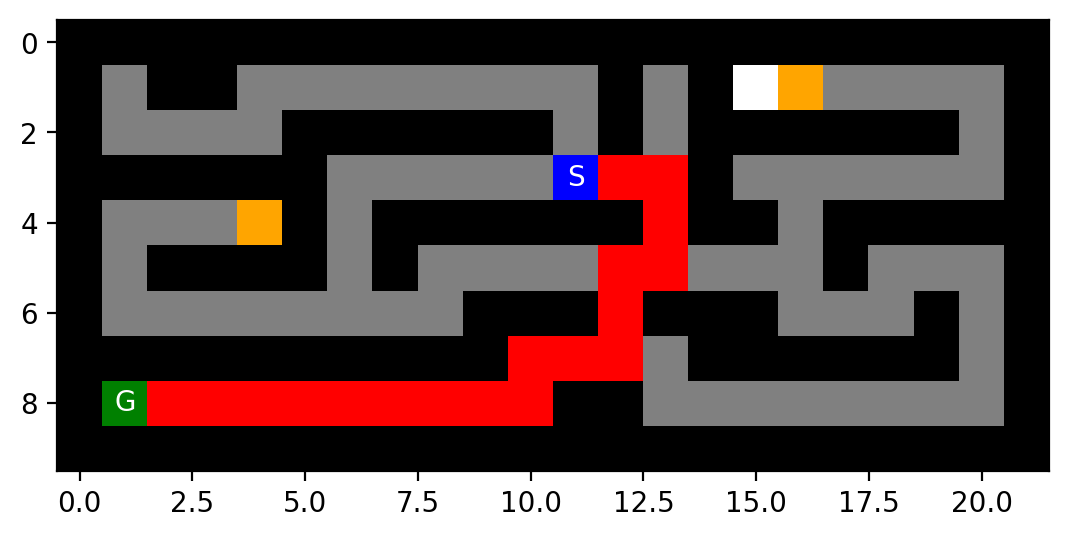

large maze: plan of 210 actions, 618 nodes expanded, max frontier size 8
plan: NNWWWWNNWWSSWWWWWWWWWWWWWWNNEENNWWNNNNNNEEEEEESSEENNEEEENNEESSEENNNNNNEEEENNNNNNNNNNWWSSWWWWSSSSSSWWSSSSWWNNWWWWWWWWWWWWNNEENNNNNNEEEEEENNNNNNNNWWWWWWSSWWWWSSSSEESSWWWWWWWWWWSSSSSSSSSSEESSSSWWSSSSEESSWWSSSSWWSS


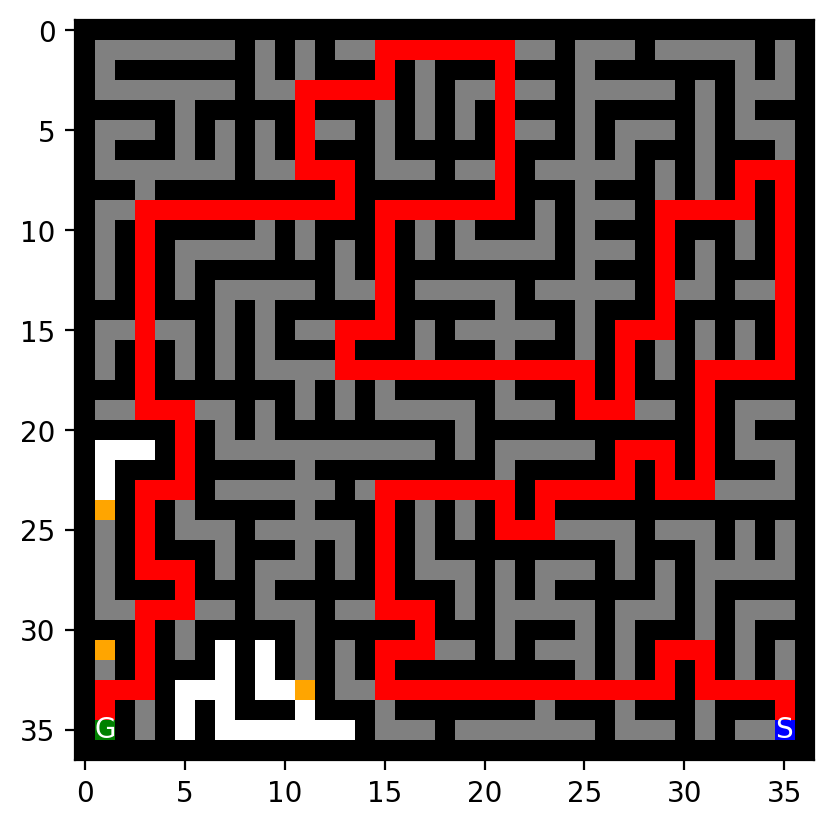

open maze: plan of 54 actions, 679 nodes expanded, max frontier size 25
plan: SSSSSWWWWWWWWWWWWWWWWSSSSSSSSSSSSSSSWWWWWWWWWWWWWWWWWW


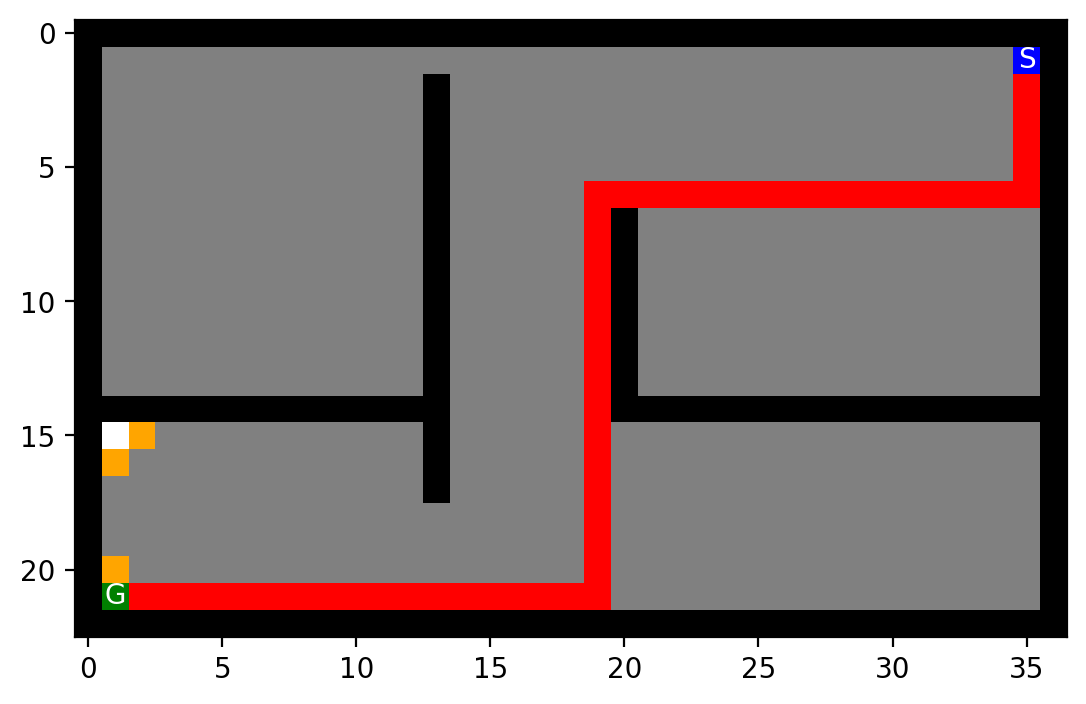

empty maze: plan of 14 actions, 92 nodes expanded, max frontier size 12
plan: NNNNNNNEEEEEEE


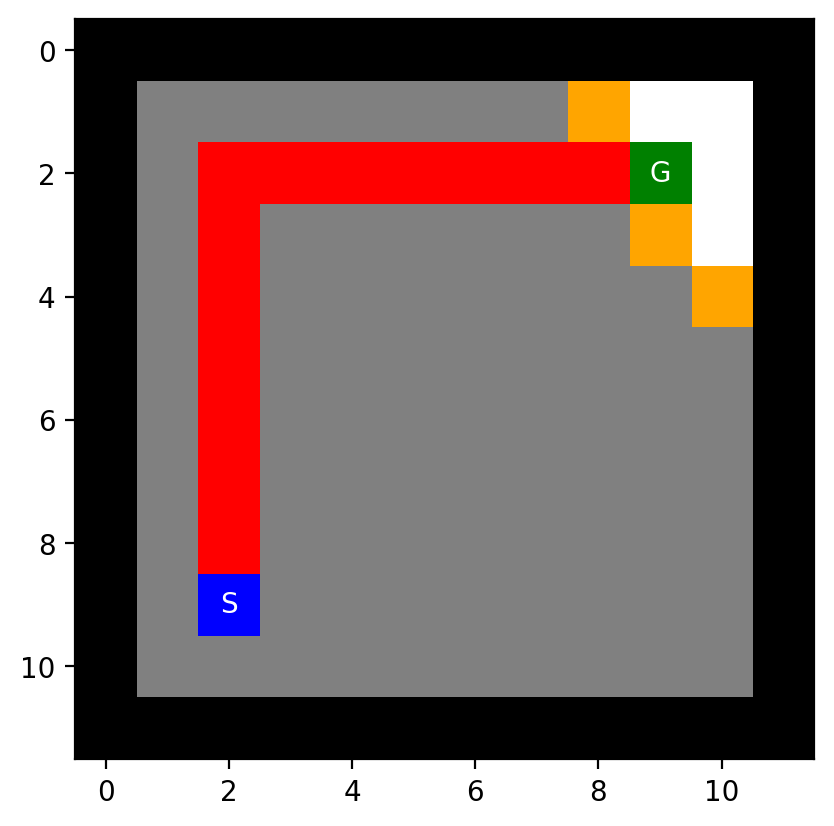

| maze | path length | # of nodes expanded |
|---|---|---|
| small | 19 | 90 |
| large | 210 | 618 |
| open | 54 | 679 |
| empty | 14 | 92 |

In [13]:
from IPython.display import Markdown, display

def mark_maze(maze, result):
    """Copy of the maze used ONLY for display: '.' = expanded square, 'F' = frontier, 'P' = final path."""
    m = np.copy(maze)
    for pos in result["visited"]:
        if m[pos] == " ": m[pos] = "."
    for pos in result["frontier"]:
        if m[pos] in (" ", "."): m[pos] = "F"
    for pos in result["positions"]:
        if m[pos] in (" ", ".", "F"): m[pos] = "P"
    return m

maze_files = {"small": "small_maze.txt", "large": "large_maze.txt", "open": "open_maze.txt", "empty": "empty_maze.txt"}

rows = []
for name, file in maze_files.items():
    with open(file) as f:
        maze = mh.parse_maze(f.read())
    start, goal = mh.find_pos(maze, "S"), mh.find_pos(maze, "G")

    result = bfs(maze, start, goal)
    rows.append(f"| {name} | {result['cost']} | {result['expanded']} |")

    print(f"{name} maze: plan of {result['cost']} actions, {result['expanded']} nodes expanded, max frontier size {result['max_frontier']}")
    print("plan:", "".join(result["actions"]))
    mh.show_maze(mark_maze(maze, result))

display(Markdown("| maze | path length | # of nodes expanded |\n|---|---|---|\n" + "\n".join(rows)))

# Task 3: Discussion [3 Points] 

Is your implementation complete and optimal? Explain why. What is the time and space complexity of each of **your** implementation?

**Complete:** yes. The maze has a finite number of states and my BFS puts every state into `reached` only once, so it always terminates and finds a goal if one is reachable.

**Optimal:** yes. Every action costs 1 and BFS expands nodes by increasing depth, so the first goal that is generated is the shallowest one, which is also the cheapest.

**Time:** $O(b^d)$ nodes in the worst case ($b$ = branching factor, $d$ = depth of the shallowest goal). Because of the `reached` set each of the $n$ states is expanded at most once, so the time is also bounded by $O(n \cdot b)$. In the experiments: small maze 90 expansions for a path of 19 steps (94 free squares); large maze 618 expansions for a path of 210 steps (647 free squares); open maze 679 expansions for a path of 54 steps (684 free squares); empty maze 92 expansions for a path of 14 steps (100 free squares).

**Space:** also $O(b^d)$, bounded by $O(n)$, because all generated nodes stay in memory (tree and `reached`) and the frontier can contain a whole layer of the search tree. This is the main weakness of BFS.

How would the planning improve if you use informed search with A* search and the Euclidean distance to the goal as the heuristic? What would the algorithm do differently?

A* would pick the node with the smallest $f(n) = g(n) + h(n)$ from a **priority queue** instead of the oldest node from a FIFO queue. The Euclidean distance $h(n) = \sqrt{(r - r_G)^2 + (c - c_G)^2}$ is a straight-line lower bound of the real path length, so it is **admissible**, and with a `reached` table that also re-opens states reached by a cheaper path, A* stays **optimal**.

What changes:

* BFS looks in all directions at the same time and expands every square closer to the start than the goal (a circle around `S`). A* prefers squares that are close to the start **and** close to the goal, so it expands mainly squares in the direction of the goal and typically far fewer nodes, especially in open mazes where the straight line is not blocked.
* The heuristic helps less in mazes with many walls (the real path can be much longer than the straight line, so $h$ is not informative) and the result is never worse than BFS in terms of path cost, but each expansion costs a bit more (priority queue operations $O(\log n)$ and the computation of $h$).
* Since the agent can only move in four directions, the Euclidean distance underestimates the real distance more than the Manhattan distance $|\Delta r| + |\Delta c|$, which is also admissible. A* with the Manhattan distance is therefore better informed and usually expands fewer nodes than with the Euclidean distance.

Your BFS implementation works fine to solve small mazes. Why would it not work for larger problems with millions of states and 100s of actions? What algorithm could be used then?

BFS needs to store **all** generated nodes, so memory (and time) grow like $O(b^d)$. With millions of states and hundreds of actions per state (e.g., $b = 100$, $d = 5$ already gives $100^5 = 10^{10}$ nodes) the `reached` table and the frontier do not fit into memory, and the search takes far too long, before a solution is found. 

Alternatives:

* **Informed search (A\*, weighted A\*, greedy best-first)** with a good heuristic, to expand only a small part of the state space (but A* still needs exponential memory in the worst case).
* **Algorithms with limited memory:** iterative deepening (IDS) or IDA\*, which need only $O(bd)$ memory, or SMA\*/RBFS.
* **Bidirectional search**, which reduces $O(b^d)$ to about $2 \cdot O(b^{d/2})$.
* For very large problems with non-optimal solutions: **beam search**, local search, or hierarchical planning and sampling-based planners.